In [1]:
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
import gebtaero_jax as gx

I11 = 0.1
cs = gx.CrossSection.from_isotropic(2e4, 4e6, 1e4).with_mass(0.75, 0.0375, 0.0625)
model = gx.straight_wing(cs, 16.0, 1.0, 0.0, 16, aero=gx.Aero.PETERS)

## Static deflection vs angle of attack (Aeroelasticity.jl `cantilever-steady`: 25 m/s, gravity off)

α (deg) | tip deflection up (m) | tip twist (deg) | lift (N)
      1 |                 2.247 |           0.952 |    77.03
      2 |                 3.976 |           1.589 |   136.35
      3 |                 5.231 |           1.942 |   179.70
      4 |                 6.172 |           2.109 |   212.66
      5 |                 6.908 |           2.157 |   238.94


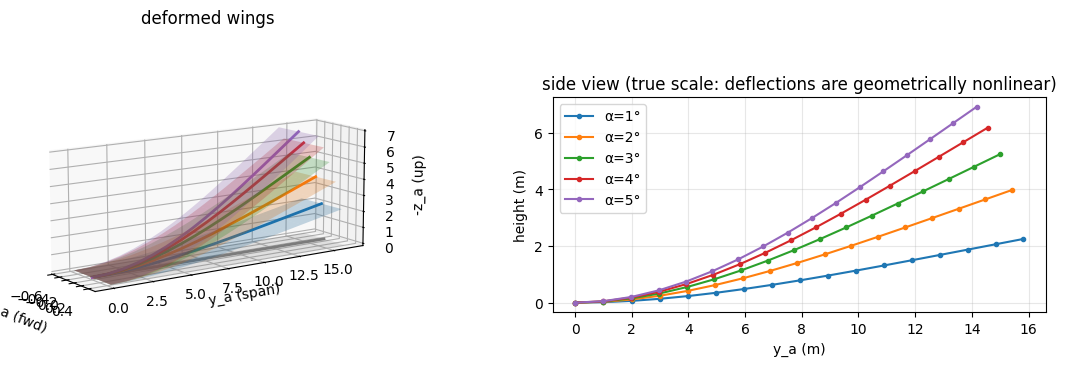

In [2]:
fig = plt.figure(figsize=(14, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax2 = fig.add_subplot(1, 2, 2)
gx.plotting.plot_wing_3d(model, None, ax=ax, color="grey", alpha=0.15)
rows = []
for i, a_deg in enumerate([1, 2, 3, 4, 5]):
    fl = gx.FlightCondition(velocity=25.0, rho=0.0889, alpha=np.radians(a_deg))
    x = gx.solve_static(model, fl, n_load_steps=4)
    out = gx.static_outputs(model, x)
    rows.append((a_deg, -out.tip_displacement[2], float(np.degrees(gx.tip_twist(model, x))), -out.root_force[2]))
    gx.plotting.plot_wing_3d(model, x, ax=ax, color=f"C{i}", alpha=0.25, label=f"α={a_deg}°")
    pts = np.asarray(gx.node_positions(model, x))
    ax2.plot(pts[:, 1], -pts[:, 2], "o-", ms=3, color=f"C{i}", label=f"α={a_deg}°")
ax.view_init(12, -35); ax.set_box_aspect((1, 4, 1.5)); ax.set_title("deformed wings")
ax2.set_aspect("equal"); ax2.set_xlabel("y_a (m)"); ax2.set_ylabel("height (m)"); ax2.grid(alpha=.3); ax2.legend()
ax2.set_title("side view (true scale: deflections are geometrically nonlinear)")
print("α (deg) | tip deflection up (m) | tip twist (deg) | lift (N)")
for r in rows:
    print(f"{r[0]:7d} | {r[1]:21.3f} | {r[2]:15.3f} | {r[3]:8.2f}")

## Exact sensitivities of the deformed shape (implicit differentiation)

In [3]:
def tip_up(params):
    cs_ = gx.CrossSection.from_isotropic(params["EI"], 4e6, params["GJ"]).with_mass(0.75, 0.0375, 0.0625)
    m = gx.straight_wing(cs_, 16.0, 1.0, params["a"], 16, aero=gx.Aero.PETERS)
    fl = gx.FlightCondition(velocity=25.0, rho=0.0889, alpha=params["alpha"])
    x = gx.solve_static(m, fl, n_load_steps=4)
    return -gx.tip_displacement(m, x)[2]

p = {"EI": 2e4, "GJ": 1e4, "a": 0.0, "alpha": np.radians(2.0)}
val, grad = jax.value_and_grad(tip_up)(p)
print(f"tip deflection = {float(val):.4f} m")
for k, g in grad.items():
    h = 1e-6 * max(abs(p[k]), 1.0)
    pp, pm = dict(p), dict(p); pp[k] += h; pm[k] -= h
    fd = (tip_up(pp) - tip_up(pm)) / (2 * h)
    print(f"d tip / d {k:<5s} AD = {float(g): .6e}   FD = {float(fd): .6e}")

tip deflection = 3.9760 m


d tip / d EI    AD = -1.593317e-04   FD = -1.593317e-04


d tip / d GJ    AD = -2.050089e-04   FD = -2.050089e-04


d tip / d a     AD =  4.612197e+00   FD =  4.612197e+00


d tip / d alpha AD =  8.379239e+01   FD =  8.379239e+01


## Trim: angle of attack giving lift = weight (GEBTAero `EquilibriumAoA`)
Newton on α, where the derivative of the *nonlinear aeroelastic* lift w.r.t. α is obtained by AD through the
equilibrium solver.

In [4]:
def net_lift(alpha, V):
    fl = gx.FlightCondition(velocity=V, rho=0.0889, alpha=alpha, gravity=9.81)
    x = gx.solve_static(model, fl, n_load_steps=3)
    return gx.lift_force(model, x)  # aerodynamic lift minus weight carried at the root

dlift = jax.value_and_grad(net_lift)
for V in [20.0, 25.0, 30.0]:
    alpha = 0.02
    for it in range(8):
        f, df = dlift(alpha, V)
        alpha = alpha - f / df
        if abs(f) < 1e-8: break
    print(f"V = {V:4.1f} m/s  ->  trim α = {np.degrees(float(alpha)):.4f}°  (residual lift {float(f):.1e} N, {it+1} Newton its)")

V = 20.0 m/s  ->  trim α = 2.8434°  (residual lift -7.9e-09 N, 4 Newton its)


V = 25.0 m/s  ->  trim α = 1.4532°  (residual lift -1.2e-09 N, 4 Newton its)


V = 30.0 m/s  ->  trim α = 0.6758°  (residual lift -4.3e-09 N, 5 Newton its)


## Flutter speed of the deformed wing vs root angle of attack (Patil, Hodges & Cesnik 2001)
At each velocity the wing is linearised about its nonlinear static equilibrium. As the static tip deflection
grows, bending/torsion/lag couple and the flutter speed drops sharply.

α = 0.0°  ->  CriticalPoint(flutter: V=32.1513 m/s, f=3.5952 Hz)


α = 0.5°  ->  CriticalPoint(flutter: V=25.9302 m/s, f=2.9794 Hz)


α = 1.0°  ->  CriticalPoint(flutter: V=23.1666 m/s, f=2.7118 Hz)


α = 2.0°  ->  CriticalPoint(flutter: V=22.9070 m/s, f=1.9060 Hz)


α = 3.0°  ->  CriticalPoint(flutter: V=22.3294 m/s, f=1.5822 Hz)


α = 4.0°  ->  CriticalPoint(flutter: V=23.6479 m/s, f=1.2317 Hz)


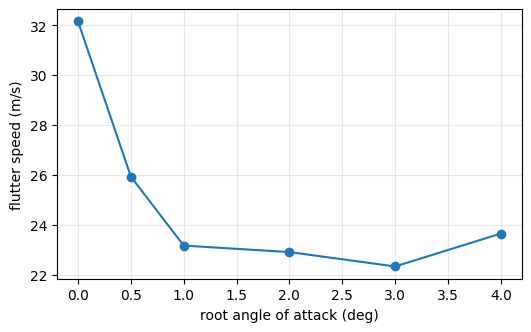

In [5]:
cs_f = gx.CrossSection.from_isotropic(2e4, 4e6, 1e4).with_mass(0.75, 1e-3 * I11, I11)
m_f = gx.straight_wing(cs_f, 16.0, 1.0, 0.0, 10, aero=gx.Aero.PETERS)
alphas = [0.0, 0.5, 1.0, 2.0, 3.0, 4.0]
vf = []
for a_deg in alphas:
    p = gx.flutter_speed(m_f, gx.FlightCondition(rho=0.0889, alpha=np.radians(a_deg)), 5.0, 40.0, n_grid=15, n_load_steps=3)
    vf.append(p.velocity); print(f"α = {a_deg:3.1f}°  ->  {p}")
plt.figure(figsize=(6, 3.5)); plt.plot(alphas, vf, "o-"); plt.grid(alpha=.3)
plt.xlabel("root angle of attack (deg)"); plt.ylabel("flutter speed (m/s)");

## Gravity-deformed flutter (GEBTAero `Patil.py` test 2)
GEBTAero reports 23.35 m/s using hand-coded, approximate aerodynamic Jacobians about the drooped wing; the exact
AD linearisation gives ~23.1 m/s.

In [6]:
cs_g = gx.CrossSection.from_isotropic(2e4, 0.0, 1e4).with_mass(0.75, 1e-3 * I11, I11)
m_g = gx.straight_wing(cs_g, 16.0, 1.0, 0.0, 10, aero=gx.Aero.PETERS)
print(gx.flutter_speed(m_g, gx.FlightCondition(rho=0.0889, gravity=9.81), 1.0, 50.0, n_grid=10, n_load_steps=4))

CriticalPoint(flutter: V=23.1343 m/s, f=2.1259 Hz)
